# Gather Movie Titles to be Analyzed for Data Exploration

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as tests

# titles = [
#     "Oppenheimer",
#     "Barbie",
#     "Dune: Part Two",
#     "Madame Web",
#     "Inside Out 2",
#     "The Odyssey",
#     "Spider-Man: Brand New Day",
#     "Hoppers",
#     "Toy Story 5",
#     "The Emoji Movie",
#     "The Human Centipede"
# ]

titles = [
    "Oppenheimer",
    "Barbie",
    "Dune: Part Two",
    "Madame Web",
    "Inside Out 2",
    "The Odyssey",
    "Spider-Man: Brand New Day",
    "Hoppers",
    "Toy Story 5",
    "The Emoji Movie",
    "The Human Centipede",
    "Parasite",
    "Everything Everywhere All at Once",
    "Spider-Man: Into the Spider-Verse",
    "Mad Max: Fury Road",
    "Get Out",
    "Whiplash",
    "Top Gun: Maverick",
    "Jurassic World",
    "Guardians of the Galaxy Vol. 3",
    "Wonka",
    "Wicked",
    "Avatar: The Way of Water",
    "Black Adam",
    "Thor: Love and Thunder",
    "Ant-Man and the Wasp: Quantumania",
    "Aquaman",
    "Ready Player One",
    "The Hunger Games: The Ballad of Songbirds & Snakes",
    "Fast X",
    "Justice League",
    "Batman v Superman: Dawn of Justice",
    "Suicide Squad",
    "Venom",
    "Transformers: Age of Extinction",
    "Cats",
    "The Last Airbender",
    "Morbius",
    "Fantastic Four",
    "Dolittle",
    "Jupiter Ascending",
]

movies = pd.DataFrame({"title": titles})
display(movies)

,title
0,Oppenheimer
1,Barbie
2,Dune: Part Two
3,Madame Web
4,Inside Out 2
5,The Odyssey
6,Spider-Man: Brand New Day
7,Hoppers
8,Toy Story 5
9,The Emoji Movie


# OMDB API Function and Calls for Rotten Tomato Scores


In [27]:
import requests

OMDB_KEY = "690401ba"

def get_movie(title):
    response = requests.get(
        "https://www.omdbapi.com/",
        params={"apikey": OMDB_KEY, "t": title},
    )
    data = response.json()

    if data.get("Response") != "True":
        print("Not found:", title)
        return None

    rt = next(
        (r["Value"] for r in data.get("Ratings", [])
         if r["Source"] == "Rotten Tomatoes"),
        None
    )

    return {
        "title": data["Title"],
        "imdb_id": data["imdbID"],
        "release_date": data.get("Released"),
        "genre": data.get("Genre"),
        "rt_score": int(rt.rstrip("%")) if rt else None
    }

records = [get_movie(title) for title in titles]

movies = pd.DataFrame(
    [record for record in records if record is not None]
)

movies["release_date"] = pd.to_datetime(
    movies["release_date"]
)

movies = movies.dropna(subset=["rt_score", "release_date"]).drop_duplicates("imdb_id")
movies.to_csv("data/movies.csv", index=False)
print("Movies kept:", len(movies))

display(movies)


Movies kept: 41


,title,imdb_id,release_date,genre,rt_score
0,Oppenheimer,tt15398776,2023-07-21,"Biography, Drama, History",93
1,Barbie,tt1517268,2023-07-21,"Adventure, Comedy, Fantasy",88
2,Dune: Part Two,tt15239678,2024-03-01,"Action, Adventure, Drama",92
3,Madame Web,tt11057302,2024-02-14,"Action, Thriller",10
4,Inside Out 2,tt22022452,2024-06-14,"Animation, Adventure, Comedy",91
5,The Odyssey,tt33764258,2026-07-17,"Action, Adventure, Fantasy",94
6,Spider-Man: Brand New Day,tt22084616,2026-07-31,"Action, Adventure",90
7,Hoppers,tt26443616,2026-03-06,"Animation, Adventure, Comedy",94
8,Toy Story 5,tt29355505,2026-06-19,"Animation, Adventure, Comedy",92
9,The Emoji Movie,tt4877122,2017-07-28,"Animation, Adventure, Comedy",6


# ArcticShift API Function to Fetch Reddit Posts

In [28]:
from datetime import timedelta
import time

ARCTIC_URL = (
    "https://arctic-shift.photon-reddit.com/api/posts/search"
)

def fetch_posts(title, release_date, subreddit):
    release = pd.Timestamp(release_date)

    end = release - pd.Timedelta(days=3)
    start = end - pd.Timedelta(days=30)

    params = {
        "subreddit": subreddit,
        "title": title,
        "after": start.strftime("%Y-%m-%d"),
        "before": end.strftime("%Y-%m-%d"),
        "limit": 100,
        "sort": "asc",
        "fields": (
            "id,title,subreddit,score,"
            "num_comments,created_utc,selftext"
        )
    }

    response = requests.get(ARCTIC_URL,params=params, timeout=60)
    response.raise_for_status()

    return response.json().get("data", [])  

# Data Gathering: ArcticShift API calls for each movie 

In [29]:
all_posts = []
failures = []

movies = pd.read_csv("data/movies.csv", parse_dates=["release_date"])

for _, movie in movies.iterrows():
    for subreddit in ["movies", "boxoffice"]:
        try:
            results = fetch_posts(
                movie["title"],
                movie["release_date"],
                subreddit
            )

            for post in results:
                post["movie_id"] = movie["imdb_id"]
                post["movie_title"] = movie["title"]

            all_posts.extend(results)

        except requests.RequestException as e:
            failures.append({
                "movie": movie["title"],
                "subreddit": subreddit,
                "error": str(e)
            })

        time.sleep(1)

posts_df = pd.DataFrame(all_posts)

print("Posts collected:", len(posts_df))
print("Failed searches:", len(failures))

display(posts_df.head())
display(pd.DataFrame(failures))


/var/folders/rn/ry_5bfb11bvcnryvb2p6pfrr0000gn/T/ipykernel_54587/2075849794.py:11: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  end = release - pd.Timedelta(days=3)
/var/folders/rn/ry_5bfb11bvcnryvb2p6pfrr0000gn/T/ipykernel_54587/2075849794.py:12: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  start = end - pd.Timedelta(days=30)


Posts collected: 728
Failed searches: 63


,created_utc,id,num_comments,score,selftext,subreddit,title,movie_id,movie_title
0,1687119110,14ctuw4,0,1,[removed],movies,Who's doing the Barbie/Oppenheimer double-feat...,tt1517268,Barbie
1,1687241398,14e2rts,0,4,,movies,Margot Robbie Takes You Inside The Barbie Drea...,tt1517268,Barbie
2,1687536344,14h2f2n,1100,15137,,movies,Official Poster for Greta Gerwig's 'Barbie',tt1517268,Barbie
3,1687551615,14h8nb7,1,1,[removed],movies,Barbie is what Hollywood needs right now,tt1517268,Barbie
4,1687590421,14hm3vm,0,1,,movies,Barbie Movie Trailer: A Sneak Peek into the Ma...,tt1517268,Barbie


,movie,subreddit,error
0,Oppenheimer,movies,422 Client Error: Unprocessable Entity for url...
1,Oppenheimer,boxoffice,422 Client Error: Unprocessable Entity for url...
2,Inside Out 2,boxoffice,422 Client Error: Unprocessable Entity for url...
3,The Odyssey,movies,422 Client Error: Unprocessable Entity for url...
4,Spider-Man: Brand New Day,movies,422 Client Error: Unprocessable Entity for url...
...,...,...,...
58,Fantastic Four,boxoffice,429 Client Error: Too Many Requests for url: h...
59,Dolittle,movies,429 Client Error: Too Many Requests for url: h...
60,Dolittle,boxoffice,429 Client Error: Too Many Requests for url: h...
61,Jupiter Ascending,movies,429 Client Error: Too Many Requests for url: h...


# Data Pre-Processing for posts_df

In [30]:
posts_df = posts_df.drop_duplicates(subset=["movie_id", "id"])
posts_df["score"] = pd.to_numeric(posts_df["score"])
posts_df["num_comments"] = pd.to_numeric(posts_df["num_comments"],)
posts_df["created_utc"] = pd.to_datetime(posts_df["created_utc"], unit="s", utc=True)
posts_df = posts_df.dropna(subset=["movie_id", "id", "created_utc"])
posts_df.to_csv("data/reddit_posts.csv", index=False)

# Aggregating posts data into unified movie_features DataFrame

In [10]:
movie_stats = (
    posts_df.groupby("movie_id")
    .agg(
        total_posts=("id", "count"),
        total_comments=("num_comments", "sum"),
        avg_post_score=("score", "mean"),
        median_post_score=("score", "median"),
        max_post_score=("score", "max"),
        subreddit_count=("subreddit", "nunique")
    ).reset_index()
)

movie_features = movies.merge(
    movie_stats,
    left_on="imdb_id",
    right_on="movie_id",
    how="left"
)

movie_features["total_posts"] = (movie_features["total_posts"].fillna(0))
movie_features.to_csv("data/movie_features.csv",)

display(movie_features.head())

,title,imdb_id,release_date,genre,rt_score,movie_id,total_posts,total_comments,avg_post_score,median_post_score,max_post_score,subreddit_count
0,Oppenheimer,tt15398776,2023-07-21,"Biography, Drama, History",93,tt15398776,100.0,2287.0,72.870000,1.0,3679.0,1.0
1,Barbie,tt1517268,2023-07-21,"Adventure, Comedy, Fantasy",88,tt1517268,100.0,5224.0,77.920000,16.0,907.0,1.0
2,Dune: Part Two,tt15239678,2024-03-01,"Action, Adventure, Drama",92,NaN,0.0,NaN,NaN,NaN,NaN,NaN
3,Madame Web,tt11057302,2024-02-14,"Action, Thriller",10,tt11057302,11.0,118.0,1.181818,1.0,3.0,1.0
4,Inside Out 2,tt22022452,2024-06-14,"Animation, Adventure, Comedy",91,tt22022452,51.0,1620.0,94.960784,23.0,2444.0,2.0


# Is Reddit engagement prior to a movies release correlated with the Rotten Tomatoes score of a movie? (tracked as the amount of total comments on posts about a given movie)

$H_0$: There is no correlation between the amount pre-release Reddit comments about a movie and the Rotten Tomatoes score of that movie.

$H_A$: There is a correlation between the amount pre-release Reddit comments about a movie and the Rotten Tomatoes score of that movie.

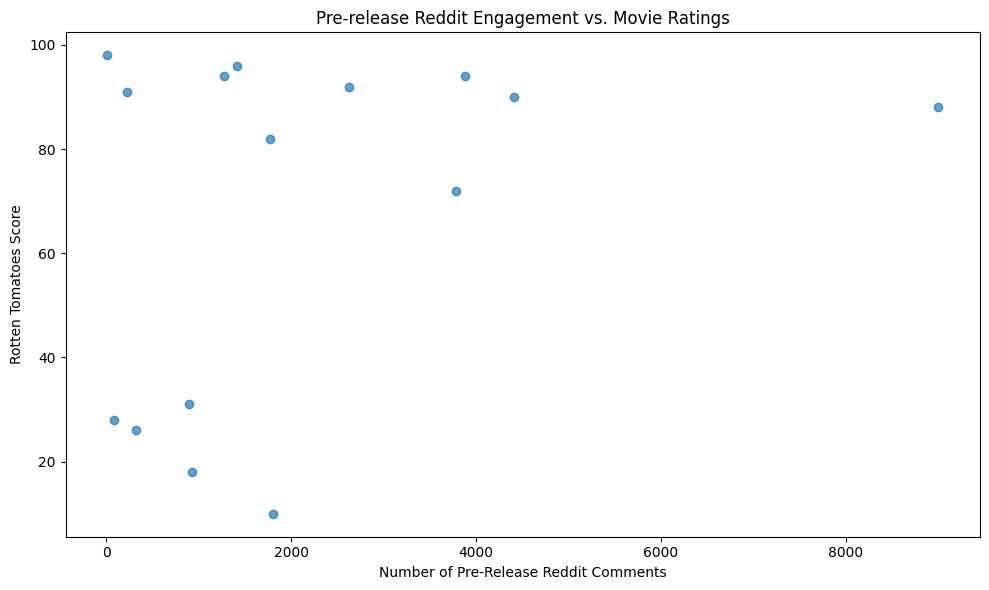

Upon applying Spearman's Rank Correlation we find that the p-value is:  0.83955826497189 and the correlation is:  0.05719394598376622


In [ ]:
graph_data = movie_features[["total_comments", "rt_score"]].dropna()
plt.figure(figsize=(10, 6))
x = graph_data["total_comments"]
y = graph_data["rt_score"]
plt.scatter(x, y, alpha=0.7)
plt.xlabel("Number of Pre-Release Reddit Comments")
plt.ylabel("Rotten Tomatoes Score")
plt.title("Pre-release Reddit Engagement vs. Movie Ratings")
plt.tight_layout()
plt.show()
# GORGEOUS graph

r, p = tests.spearmanr(x, y)
print("Upon applying Spearman's Rank Correlation we find that the p-value is: ", p, "and the correlation is: ", r)

# Sometimes the data is inconsistent due to rate limiting causing request 
# trouble, so we will use the results of the last test run. 


# Conclusion

Because p > 0.05, we fail to reject the null hypothesis. Therefore, there is not significant evidence that the amount of Reddit engagement a movie gets pre-release is correlated with it's Rotten Tomatoes score. 

# Question 2: Is the number of comments on a Reddit post correlated with the post's score?

$H_0$: There is no correlation between a post's number of comments and its score.

$H_A$: There is a correlation between a post's number of comments and its score.

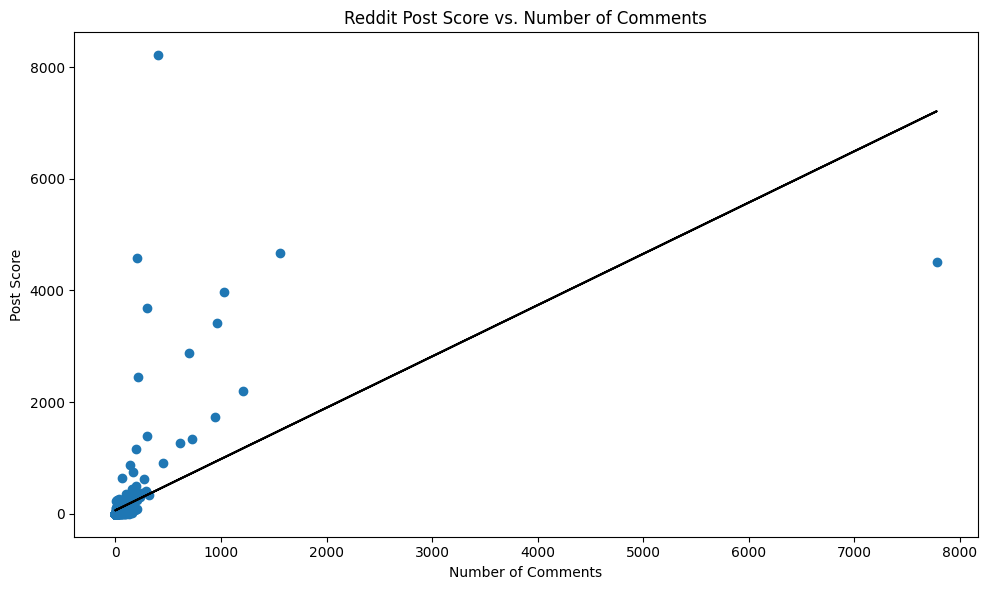

Based off our linear regression we find that: slope = 0.9186063499472201, r^2 = 0.29341009057653666, p = 3.139834352267927e-50
Is p < 0.05? True


In [9]:
x = posts_df["num_comments"]
y = posts_df["score"]
linreg = tests.linregress(x, y)

plt.figure(figsize=(10, 6))
plt.scatter(x, y)
plt.plot(x, linreg.intercept + linreg.slope * x, color="black")
plt.xlabel("Number of Comments")
plt.ylabel("Post Score")
plt.title("Reddit Post Score vs. Number of Comments")
plt.tight_layout()
plt.show()

print(f"Based off our linear regression we find that: slope = {linreg.slope}, r^2 = {linreg.rvalue ** 2}, p = {linreg.pvalue}")
print(f"Is p < 0.05? {linreg.pvalue < 0.05}")

Conclusion: Since p < 0.05, we reject the null hypothesis. The number of comments is correlated with post score.

# Do action movies have different average Rotten Tomatoes scores than movies that aren't within the Action genre?

$H_0$: The two groups have different average Rotten Tomatoes scores.

$H_A$: The two groups have equal average Rotten Tomatoes scores.

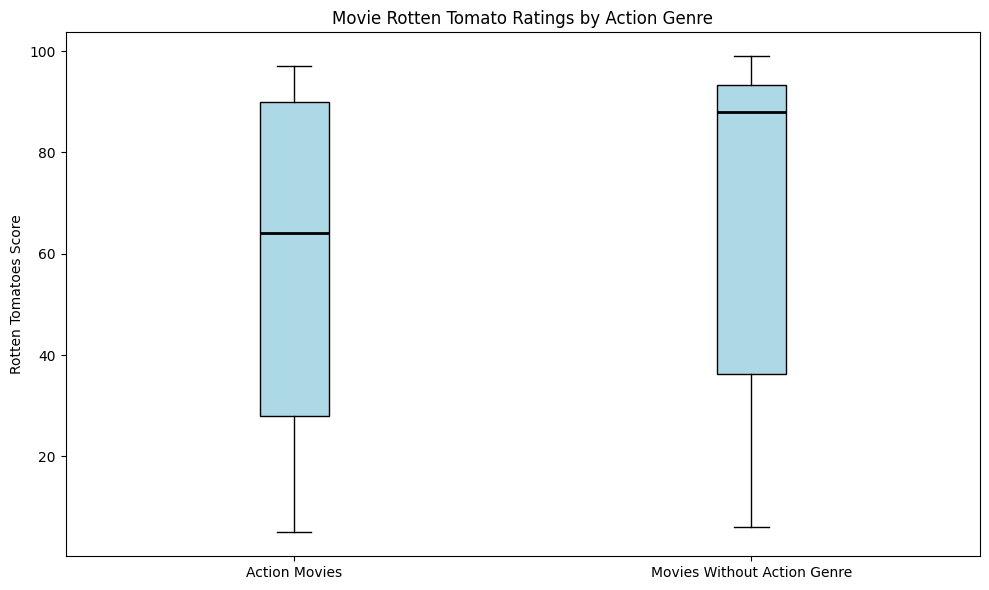

Average Action movie score: 58.2
Average Other movie score: 67.125
T test p-value: 0.40793471735170755


In [34]:
data = movies[["genre", "rt_score"]].dropna()
action_movies = data["genre"].str.contains("Action")

action = data.loc[action_movies, "rt_score"]
other = data.loc[~action_movies, "rt_score"]

plt.figure(figsize=(10, 6))
plt.boxplot([action, other], patch_artist=True,
            boxprops={"facecolor": "lightblue"},
            medianprops={"color": "black", "linewidth": 2})
plt.xticks([1, 2], ["Action Movies", "Movies Without Action Genre"])
plt.ylabel("Rotten Tomatoes Score")
plt.title("Movie Rotten Tomato Ratings by Action Genre")
plt.tight_layout()
plt.show()

t, p = tests.ttest_ind(action, other, equal_var=False)
print("Average Action movie score:", action.mean())
print("Average Other movie score:", other.mean())
print("T test p-value:", p)

# Conclusion

Because p < 0.05, we fail to reject the null hypothesis. This means that there is not evidence that action movies and non-action movies in our sample have different average rotten tomato scores.
